In [31]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

import plotly.express as px
import plotly.graph_objects as go

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [32]:
#import dataset
campus = pd.read_csv("/content/campus_meta.csv")
building = pd.read_csv("/content/building_meta.csv")

print("Campus Information")
display(campus)

print("Building Information")
display(building.head())

Campus Information


,id,name,capacity
0,1,Bundoora,26000
1,2,Albury-Wodonga,800
2,3,Bendigo,5000
3,4,Mildura,500
4,5,Shepparton,700


Building Information


,campus_id,id,built_year,category,gross_floor_area,room_area,capacity
0,1,1,NaN,other,NaN,NaN,NaN
1,1,2,NaN,other,NaN,NaN,NaN
2,1,3,NaN,other,NaN,NaN,NaN
3,1,4,1967.0,mixed use,145558.14,1790.17,79.0
4,1,5,1899.0,other,0.00,NaN,NaN


In [33]:
#load and aggregate electricity consumption
file_path = "/content/building_consumption.csv"

chunksize = 500000

hourly_data = []

for chunk in pd.read_csv(
    file_path,
    chunksize=chunksize
):

    chunk["timestamp"] = pd.to_datetime(
        chunk["timestamp"],
        errors="coerce"
    )

    chunk = chunk.dropna(
        subset=["timestamp", "consumption", "campus_id"]
    )

    chunk["timestamp"] = chunk["timestamp"].dt.floor("h")

    grouped = chunk.groupby(
        ["campus_id", "timestamp"]
    )["consumption"].sum().reset_index()

    hourly_data.append(grouped)

    print("Processed", len(chunk), "records")

df = pd.concat(hourly_data, ignore_index=True)

df = df.groupby(
    ["campus_id", "timestamp"]
)["consumption"].sum().reset_index()

df = df.sort_values("timestamp")

print("Hourly dataset created!")
display(df.head())

Processed 500000 records
Processed 500000 records
Processed 500000 records
Processed 500000 records
Processed 500000 records
Processed 500000 records
Processed 500000 records
Processed 500000 records
Processed 500000 records
Processed 500000 records
Processed 500000 records
Processed 500000 records
Processed 485646 records
Hourly dataset created!


,campus_id,timestamp,consumption
0,1,2018-01-01 00:00:00,1228.47237
1,1,2018-01-01 01:00:00,1646.40270
2,1,2018-01-01 02:00:00,1719.00139
3,1,2018-01-01 03:00:00,1717.78634
4,1,2018-01-01 04:00:00,1630.73694


In [34]:
#data cleaning and preprocessing
df["consumption"] = pd.to_numeric(
    df["consumption"],
    errors="coerce"
)

df = df.dropna(
    subset=["timestamp", "consumption"]
)

df = df[df["consumption"] >= 0]

df["hour"] = df["timestamp"].dt.hour
df["day"] = df["timestamp"].dt.day
df["month"] = df["timestamp"].dt.month
df["day_of_week"] = df["timestamp"].dt.dayofweek

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
Index: 98281 entries, 0 to 37837
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   campus_id    98281 non-null  int64         
 1   timestamp    98281 non-null  datetime64[ns]
 2   consumption  98281 non-null  float64       
 3   hour         98281 non-null  int32         
 4   day          98281 non-null  int32         
 5   month        98281 non-null  int32         
 6   day_of_week  98281 non-null  int32         
 7   is_weekend   98281 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int32(4), int64(2)
memory usage: 5.2 MB
None
          campus_id                      timestamp   consumption  \
count  98281.000000                          98281  98281.000000   
mean       1.946602  2020-04-02 10:49:39.456863232    898.177315   
min        1.000000            2018-01-01 00:00:00      0.104000   
25%        1.000000            2019-04-21 19:00:00 

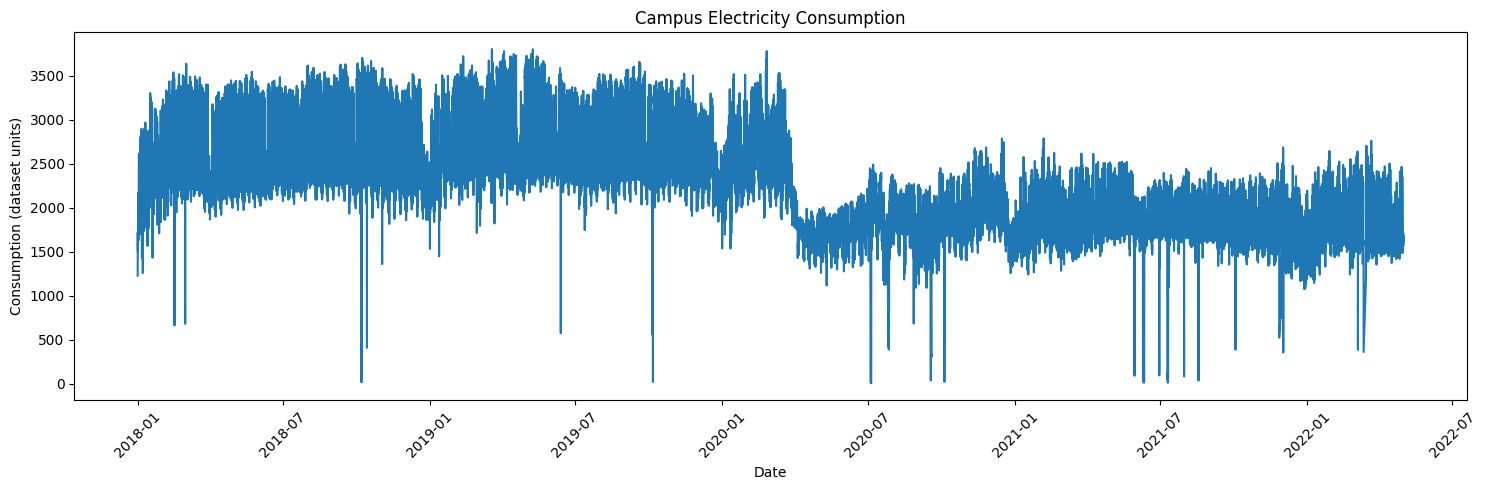

In [35]:
# Explore electricity consumption
plt.figure(figsize=(15, 5))

plt.plot(
    df[df["campus_id"] == 1]["timestamp"],
    df[df["campus_id"] == 1]["consumption"]
)

plt.title("Campus Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Consumption (dataset units)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

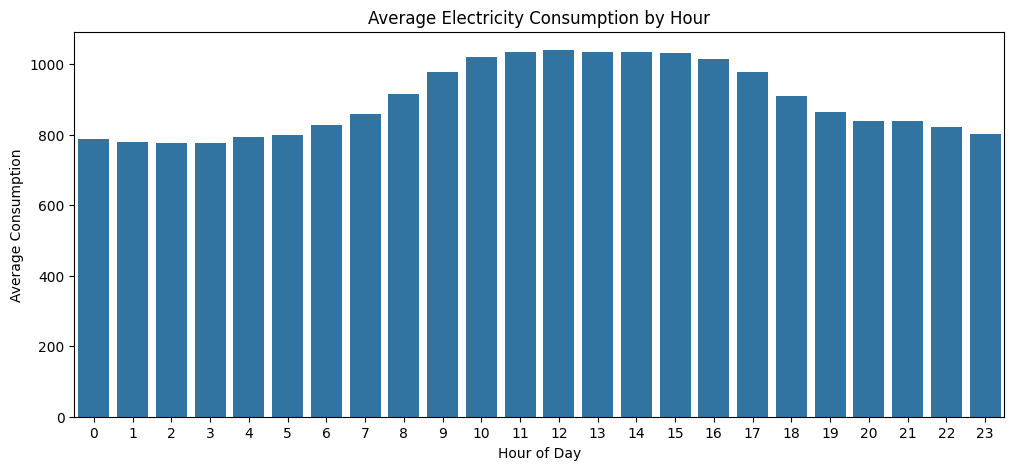

In [36]:
#Hourly consumption analysis
hourly_usage = df.groupby(
    "hour"
)["consumption"].mean().reset_index()

plt.figure(figsize=(12, 5))

sns.barplot(
    data=hourly_usage,
    x="hour",
    y="consumption"
)

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Consumption")

plt.show()

In [37]:
#Prepare Machine Learning feature
def create_features(data):

    data = data.copy()

    data["lag_1"] = data["consumption"].shift(1)

    data["lag_24"] = data["consumption"].shift(24)

    data["lag_168"] = data["consumption"].shift(168)

    data["rolling_mean_24"] = (
        data["consumption"]
        .shift(1)
        .rolling(24)
        .mean()
    )

    data["hour"] = data["timestamp"].dt.hour
    data["day"] = data["timestamp"].dt.day
    data["month"] = data["timestamp"].dt.month

    data["day_of_week"] = (
        data["timestamp"].dt.dayofweek
    )

    data["is_weekend"] = (
        data["day_of_week"] >= 5
    ).astype(int)

    return data


# Use one selected campus for training
campus_id = 1

model_data = df[
    df["campus_id"] == campus_id
][["timestamp", "consumption"]].copy()

# Combine duplicate timestamps and fill missing hourly intervals
model_data = (
    model_data.groupby("timestamp")["consumption"]
    .sum()
    .reset_index()
)

model_data = (
    model_data.set_index("timestamp")
    .asfreq("h")
)

model_data["consumption"] = (
    model_data["consumption"].fillna(0)
)

model_data = model_data.reset_index()

model_data = create_features(model_data)

model_data = model_data.dropna()

print(model_data.head())

              timestamp  consumption       lag_1      lag_24     lag_168  \
168 2018-01-08 00:00:00   1839.43002  1886.02754  1777.50818  1228.47237   
169 2018-01-08 01:00:00   1838.55096  1839.43002  1697.31294  1646.40270   
170 2018-01-08 02:00:00   1856.57888  1838.55096  1684.09590  1719.00139   
171 2018-01-08 03:00:00   1882.10044  1856.57888  1698.03254  1717.78634   
172 2018-01-08 04:00:00   1962.92104  1882.10044  1731.58804  1630.73694   

     rolling_mean_24  hour  day  month  day_of_week  is_weekend  
168      1680.562038     0    8      1            0           0  
169      1683.142115     1    8      1            0           0  
170      1689.027032     2    8      1            0           0  
171      1696.213823     3    8      1            0           0  
172      1703.883319     4    8      1            0           0  


In [38]:
#Train the machine learning model
features = [
    "hour",
    "day",
    "month",
    "day_of_week",
    "is_weekend",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24"
]

X = model_data[features]

y = model_data["consumption"]

# Chronological 80:20 split
split = int(len(model_data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Machine Learning model trained successfully!")

Machine Learning model trained successfully!


In [39]:
#Evaluate model performance
predictions = model.predict(X_test)

mae = mean_absolute_error(
    y_test,
    predictions
)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

r2 = r2_score(
    y_test,
    predictions
)

print("Model Performance")

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

Model Performance
MAE: 75.101
RMSE: 166.469
R2 Score: 0.794


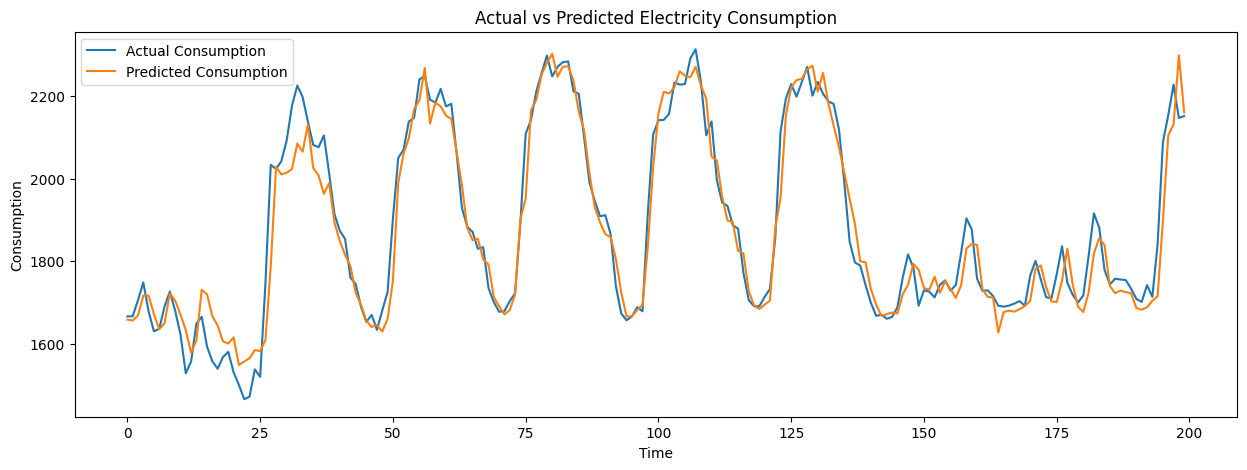

In [40]:
#Actual vs predicted evaluation
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": predictions
})

plt.figure(figsize=(15, 5))

plt.plot(
    results["Actual"].values[:200],
    label="Actual Consumption"
)

plt.plot(
    results["Predicted"].values[:200],
    label="Predicted Consumption"
)

plt.title("Actual vs Predicted Electricity Consumption")

plt.xlabel("Time")
plt.ylabel("Consumption")

plt.legend()
plt.show()

In [41]:
#Prediict the next 24 hours
history = model_data[
    ["timestamp", "consumption"]
].copy()

forecast = []

for i in range(24):

    next_time = (
        history["timestamp"].iloc[-1]
        + pd.Timedelta(hours=1)
    )

    row = pd.DataFrame({
        "timestamp": [next_time],
        "consumption": [np.nan]
    })

    combined = pd.concat(
        [history, row],
        ignore_index=True
    )

    temp = create_features(
        combined
    )

    latest = temp.iloc[[-1]]

    prediction = model.predict(
        latest[features]
    )[0]

    prediction = max(0, prediction)

    forecast.append({
        "timestamp": next_time,
        "predicted_consumption": prediction
    })

    history = pd.concat([
        history,
        pd.DataFrame({
            "timestamp": [next_time],
            "consumption": [prediction]
        })
    ], ignore_index=True)

forecast_df = pd.DataFrame(forecast)

display(forecast_df)

,timestamp,predicted_consumption
0,2022-05-01 00:00:00,1516.186372
1,2022-05-01 01:00:00,1515.977924
2,2022-05-01 02:00:00,1507.467831
3,2022-05-01 03:00:00,1504.052945
4,2022-05-01 04:00:00,1507.194308
5,2022-05-01 05:00:00,1511.048961
6,2022-05-01 06:00:00,1538.122788
7,2022-05-01 07:00:00,1514.767566
8,2022-05-01 08:00:00,1505.832832
9,2022-05-01 09:00:00,1516.534580


In [42]:
#Build intercactive streamlite dashboard

%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import zipfile
import plotly.express as px
import plotly.graph_objects as go

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---------------------------------
# PAGE CONFIGURATION
# ---------------------------------

st.set_page_config(
    page_title="Campus Energy Dashboard",
    page_icon="⚡",
    layout="wide"
)

st.title("⚡ Campus Energy Analytics Dashboard")
st.caption(
    "Machine Learning Based Electricity Consumption "
    "Prediction and Energy Optimization System"
)

ZIP_PATH = "archive (1).zip"

# ---------------------------------
# LOAD DATASET
# ---------------------------------

@st.cache_data(show_spinner="Loading electricity dataset...")
def load_data():

    with zipfile.ZipFile(ZIP_PATH) as z:

        campus = pd.read_csv(
            z.open("campus_meta.csv")
        )

        chunks = []

        with z.open("building_consumption.csv") as f:

            for chunk in pd.read_csv(
                f,
                chunksize=500000
            ):

                chunk["timestamp"] = pd.to_datetime(
                    chunk["timestamp"],
                    errors="coerce"
                )

                chunk = chunk.dropna(
                    subset=["timestamp", "consumption"]
                )

                chunk = chunk[
                    chunk["consumption"] >= 0
                ]

                chunk["timestamp"] = (
                    chunk["timestamp"].dt.floor("h")
                )

                grouped = chunk.groupby(
                    ["campus_id", "timestamp"]
                )["consumption"].sum().reset_index()

                chunks.append(grouped)

    df = pd.concat(chunks, ignore_index=True)

    df = df.groupby(
        ["campus_id", "timestamp"]
    )["consumption"].sum().reset_index()

    return df, campus


try:
    df, campus = load_data()

except Exception as e:
    st.error(f"Dataset loading error: {e}")
    st.stop()

# ---------------------------------
# SIDEBAR
# ---------------------------------

st.sidebar.header("Dashboard Settings")

campus_options = dict(
    zip(campus["name"], campus["id"])
)

selected_name = st.sidebar.selectbox(
    "Select Campus",
    list(campus_options.keys())
)

selected_id = campus_options[selected_name]

cost_per_unit = st.sidebar.number_input(
    "Electricity cost per unit (₹)",
    min_value=0.0,
    value=8.0,
    step=0.5
)

saving_percent = st.sidebar.slider(
    "Target energy saving (%)",
    min_value=5,
    max_value=30,
    value=10
)

data = df[
    df["campus_id"] == selected_id
].copy()

data = data.sort_values("timestamp")

if data.empty:
    st.warning("No data available for this campus.")
    st.stop()

# ---------------------------------
# DATE FILTER
# ---------------------------------

st.sidebar.subheader("Date Filter")

min_date = data["timestamp"].min().date()
max_date = data["timestamp"].max().date()

date_range = st.sidebar.date_input(
    "Select date range",
    value=(min_date, max_date),
    min_value=min_date,
    max_value=max_date
)

if len(date_range) == 2:

    start_date, end_date = date_range

    filtered = data[
        (data["timestamp"].dt.date >= start_date) &
        (data["timestamp"].dt.date <= end_date)
    ].copy()

else:
    filtered = data.copy()

if filtered.empty:
    st.warning("No records found for the selected date range.")
    st.stop()

# ---------------------------------
# KPI CARDS
# ---------------------------------

total_energy = filtered["consumption"].sum()

average_energy = filtered["consumption"].mean()

peak_energy = filtered["consumption"].max()

peak_time = filtered.loc[
    filtered["consumption"].idxmax(),
    "timestamp"
]

estimated_cost = total_energy * cost_per_unit

potential_saving = (
    total_energy * saving_percent / 100
)

estimated_saving = (
    potential_saving * cost_per_unit
)

st.subheader("Energy Consumption Overview")

c1, c2, c3, c4 = st.columns(4)

c1.metric(
    "Total Consumption",
    f"{total_energy:,.2f}"
)

c2.metric(
    "Average Hourly Usage",
    f"{average_energy:,.2f}"
)

c3.metric(
    "Peak Consumption",
    f"{peak_energy:,.2f}"
)

c4.metric(
    "Estimated Electricity Cost",
    f"₹{estimated_cost:,.2f}"
)

st.caption(
    f"Highest usage recorded at: {peak_time}"
)

st.divider()

# ---------------------------------
# CONSUMPTION TREND
# ---------------------------------

st.subheader("📈 Electricity Consumption Trend")

fig = px.line(
    filtered,
    x="timestamp",
    y="consumption",
    title="Hourly Electricity Consumption",
    labels={
        "timestamp": "Date and Time",
        "consumption": "Consumption (dataset units)"
    }
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified"
)

st.plotly_chart(fig, use_container_width=True)

# ---------------------------------
# DAILY CONSUMPTION
# ---------------------------------

st.subheader("📅 Daily Energy Consumption")

daily = filtered.copy()

daily["date"] = daily["timestamp"].dt.date

daily_data = daily.groupby(
    "date"
)["consumption"].sum().reset_index()

fig2 = px.bar(
    daily_data,
    x="date",
    y="consumption",
    title="Daily Electricity Usage",
    labels={
        "date": "Date",
        "consumption": "Consumption"
    }
)

st.plotly_chart(fig2, use_container_width=True)

# ---------------------------------
# HOURLY USAGE ANALYSIS
# ---------------------------------

st.subheader("⏰ Peak Usage Time Analysis")

filtered["hour"] = filtered["timestamp"].dt.hour

hourly = filtered.groupby(
    "hour"
)["consumption"].mean().reset_index()

fig3 = px.bar(
    hourly,
    x="hour",
    y="consumption",
    title="Average Consumption by Hour",
    labels={
        "hour": "Hour of Day",
        "consumption": "Average Consumption"
    }
)

st.plotly_chart(fig3, use_container_width=True)

# ---------------------------------
# MACHINE LEARNING MODEL
# ---------------------------------

st.divider()

st.subheader("🤖 Machine Learning Prediction")

st.write(
    "Random Forest Regressor is used to predict "
    "the next 24 hours of electricity consumption."
)

# Use complete campus history for model training
model_data = data[
    ["timestamp", "consumption"]
].copy()

model_data = model_data.groupby(
    "timestamp"
)["consumption"].sum().reset_index()

model_data = (
    model_data.set_index("timestamp")
    .asfreq("h")
)

model_data["consumption"] = (
    model_data["consumption"].fillna(0)
)

model_data = model_data.reset_index()

# Feature engineering
def make_features(d):

    d = d.copy()

    d["hour"] = d["timestamp"].dt.hour
    d["day"] = d["timestamp"].dt.day
    d["month"] = d["timestamp"].dt.month

    d["day_of_week"] = (
        d["timestamp"].dt.dayofweek
    )

    d["is_weekend"] = (
        d["day_of_week"] >= 5
    ).astype(int)

    d["lag_1"] = d["consumption"].shift(1)
    d["lag_24"] = d["consumption"].shift(24)
    d["lag_168"] = d["consumption"].shift(168)

    d["rolling_mean_24"] = (
        d["consumption"]
        .shift(1)
        .rolling(24)
        .mean()
    )

    return d

model_data = make_features(model_data).dropna()

features = [
    "hour",
    "day",
    "month",
    "day_of_week",
    "is_weekend",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24"
]

if len(model_data) < 200:
    st.warning(
        "Not enough historical records to train the model."
    )
    st.stop()

X = model_data[features]
y = model_data["consumption"]

split = int(len(model_data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

@st.cache_resource
def train_model(X_train, y_train):

    rf = RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    return rf

model = train_model(X_train, y_train)

# Model evaluation
test_predictions = model.predict(X_test)

mae = mean_absolute_error(
    y_test,
    test_predictions
)

rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

r2 = r2_score(
    y_test,
    test_predictions
)

m1, m2, m3 = st.columns(3)

m1.metric("MAE", f"{mae:.3f}")
m2.metric("RMSE", f"{rmse:.3f}")
m3.metric("R² Score", f"{r2:.3f}")

# ---------------------------------
# NEXT 24 HOURS FORECAST
# ---------------------------------

history = model_data[
    ["timestamp", "consumption"]
].copy()

forecast = []

for i in range(24):

    next_time = (
        history["timestamp"].iloc[-1]
        + pd.Timedelta(hours=1)
    )

    next_row = pd.DataFrame({
        "timestamp": [next_time],
        "consumption": [np.nan]
    })

    combined = pd.concat(
        [history, next_row],
        ignore_index=True
    )

    temp = make_features(combined)

    prediction = model.predict(
        temp[features].iloc[[-1]]
    )[0]

    prediction = max(0, prediction)

    forecast.append({
        "timestamp": next_time,
        "predicted_consumption": prediction
    })

    history = pd.concat([
        history,
        pd.DataFrame({
            "timestamp": [next_time],
            "consumption": [prediction]
        })
    ], ignore_index=True)

forecast_df = pd.DataFrame(forecast)

st.subheader("🔮 Next 24 Hours Consumption Forecast")

fig4 = px.line(
    forecast_df,
    x="timestamp",
    y="predicted_consumption",
    markers=True,
    title="Predicted Electricity Consumption"
)

st.plotly_chart(fig4, use_container_width=True)

st.metric(
    "Predicted Next 24 Hours Consumption",
    f"{forecast_df['predicted_consumption'].sum():,.2f}"
)

# ---------------------------------
# ENERGY OPTIMIZATION
# ---------------------------------

st.divider()

st.subheader("💡 Smart Energy Optimization Recommendations")

peak_hours = (
    hourly.sort_values(
        "consumption",
        ascending=False
    ).head(3)
)

low_hours = (
    hourly.sort_values(
        "consumption"
    ).head(3)
)

st.write("### High Energy Usage Periods")

for _, row in peak_hours.iterrows():

    st.warning(
        f"High average usage at {int(row['hour']):02d}:00"
    )

st.write("### Recommended Low Usage Periods")

for _, row in low_hours.iterrows():

    st.success(
        f"Consider scheduling flexible electricity usage "
        f"around {int(row['hour']):02d}:00, "
        f"subject to campus operating requirements."
    )

st.write("### Estimated Energy Saving Opportunity")

st.metric(
    "Potential Energy Saving",
    f"{potential_saving:,.2f} dataset units"
)

st.metric(
    "Potential Cost Saving",
    f"₹{estimated_saving:,.2f}"
)

st.caption(
    "Savings are scenario estimates based on your selected "
    "saving percentage and assumed electricity tariff. "
    "They are not measured or guaranteed savings."
)

# ---------------------------------
# ACTUAL VS PREDICTED
# ---------------------------------

st.divider()

st.subheader("📊 Actual vs Predicted Consumption")

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": test_predictions
})

comparison["Index"] = range(len(comparison))

comparison_long = comparison.melt(
    id_vars="Index",
    value_vars=["Actual", "Predicted"],
    var_name="Type",
    value_name="Consumption"
)

fig5 = px.line(
    comparison_long,
    x="Index",
    y="Consumption",
    color="Type",
    title="Model Performance Comparison"
)

st.plotly_chart(fig5, use_container_width=True)

# ---------------------------------
# DOWNLOAD REPORT
# ---------------------------------

st.subheader("📥 Download Energy Report")

csv = filtered.to_csv(index=False).encode("utf-8")

st.download_button(
    label="Download Consumption CSV",
    data=csv,
    file_name="campus_energy_report.csv",
    mime="text/csv"
)

st.success("Campus Energy Dashboard Loaded Successfully!")


Overwriting app.py


In [44]:
# Write requirements.txt file with streamlit dashboard dependencies
with open("requirements.txt", "w") as f:
    f.write("""streamlit\npandas\nnumpy\nscikit-learn\nplotly\n""")

from google.colab import files

# Download app.py
files.download("app.py")

# Download requirements.txt
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
# Access and download the README file from sample_data folder
files.download("sample_data/README.md")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [53]:
import os
import shutil
from google.colab import files

# 1. Download model_training.ipynb (if it exists)
try:
    files.download("model_training.ipynb")
except Exception as e:
    print("Note: Could not download model_training.ipynb yet:", e)

# 2. Write .gitignore programmatically using Python instead of %%writefile magic
gitignore_content = """__pycache__/
*.pyc
.ipynb_checkpoints/
.venv/
venv/
.env
*.joblib
*.pkl
.DS_Store
"""

with open(".gitignore", "w") as f:
    f.write(gitignore_content)

print(".gitignore file successfully created!")

# 3. Download the generated .gitignore
try:
    files.download(".gitignore")
except Exception as e:
    print("Note: Could not download .gitignore:", e)

# 4. Create screenshots directory and compress it
os.makedirs("screenshots", exist_ok=True)
print("Screenshots folder created!")

Note: Could not download model_training.ipynb yet: Cannot find file: model_training.ipynb
.gitignore file successfully created!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Screenshots folder created!
